# 04 · Financial Stress Score
The full methodology is in `docs/stress_score_methodology.md`. In short, there are seven factors. Each is scaled from 0 to 100 between a benchmark "healthy" value and a "maximum stress" value, then weighted.

| Factor | 0 stress | 100 stress | Weight |
|---|---|---|---|
| Savings margin (6m) | ≥ 20% | ≤ −10% | 20 |
| Fixed obligation ratio (6m) | ≤ 30% | ≥ 60% | 20 |
| Emergency buffer | ≥ 6 months | ≤ 0.5 month | 20 |
| Income instability (CV) | ≤ 0.10 | ≥ 0.60 | 10 |
| Expense growth (de-seasonalised, 6m) | ≤ 0% | ≥ +25% | 10 |
| Balance trend (6m, in months of income) | ≥ +0.5 | ≤ −1.0 | 10 |
| Deficit & borrowing frequency | 0 | 1 | 10 |

In [1]:
import sys, json
from pathlib import Path
import pandas as pd, numpy as np
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
from stress_score import FACTORS, customer_factors, score, scale
cm = pd.read_csv(ROOT / "data/analytics/customer_month.csv")
f = customer_factors(cm, cm["year_month"].max())
s = score(f)
s[["customer_id","stress_score","stress_band","top_stress_driver"] + [c for c in s.columns if c.startswith("sub_")]].sort_values("stress_score", ascending=False).head(10)

,customer_id,stress_score,stress_band,top_stress_driver,sub_savings_margin,sub_fixed_obligations,sub_emergency_buffer,sub_income_instability,sub_expense_growth,sub_balance_trend,sub_deficit_borrowing
84,C0085,82.50,Critical,savings_margin,100.00,100.00,100.00,1.80,67.50,55.60,100.00
18,C0019,77.50,High,savings_margin,100.00,9.20,100.00,57.00,100.00,100.00,100.00
75,C0076,74.50,High,emergency_buffer,93.50,77.20,100.00,0.00,54.90,48.80,100.00
90,C0091,74.30,High,fixed_obligations,99.70,100.00,94.20,15.70,0.00,73.00,66.70
58,C0059,73.80,High,savings_margin,100.00,8.70,64.50,91.60,100.00,100.00,100.00
114,C0115,73.60,High,savings_margin,100.00,100.00,98.70,0.00,0.00,38.80,100.00
21,C0022,73.20,High,savings_margin,100.00,100.00,100.00,0.00,0.00,65.60,66.70
10,C0011,72.40,High,savings_margin,100.00,100.00,96.90,0.00,0.00,29.90,100.00
102,C0103,69.40,High,savings_margin,100.00,21.80,44.20,77.40,84.10,100.00,100.00
51,C0052,65.90,High,savings_margin,100.00,69.70,95.50,14.70,0.00,14.20,100.00


## Worked example: one customer, step by step

In [3]:
cid = s.sort_values("stress_score", ascending=False).iloc[3]["customer_id"]
r = s.set_index("customer_id").loc[cid]
rows = []
for name, (col, z, h, w) in FACTORS.items():
    rows.append(dict(factor=name, raw_value=round(r[col], 3), zero_stress_at=z, max_stress_at=h,
                     sub_score=r[f"sub_{name}"], weight=w, points=r[f"contrib_{name}"]))
t = pd.DataFrame(rows); display(t)
print(f"{cid}: score = sum(points) = {t.points.sum():.1f} -> band {r['stress_band']}")

,factor,raw_value,zero_stress_at,max_stress_at,sub_score,weight,points
0,savings_margin,-0.10,0.20,-0.10,99.70,20,19.94
1,fixed_obligations,0.64,0.30,0.60,100.00,20,20.00
2,emergency_buffer,0.82,6.00,0.50,94.20,20,18.84
3,income_instability,0.18,0.10,0.60,15.70,10,1.57
4,expense_growth,-0.02,0.00,0.25,0.00,10,0.00
5,balance_trend,-0.59,0.50,-1.00,73.00,10,7.30
6,deficit_borrowing,0.67,0.00,1.00,66.70,10,6.67


C0091: score = sum(points) = 74.3 -> band High


## Distribution and drivers

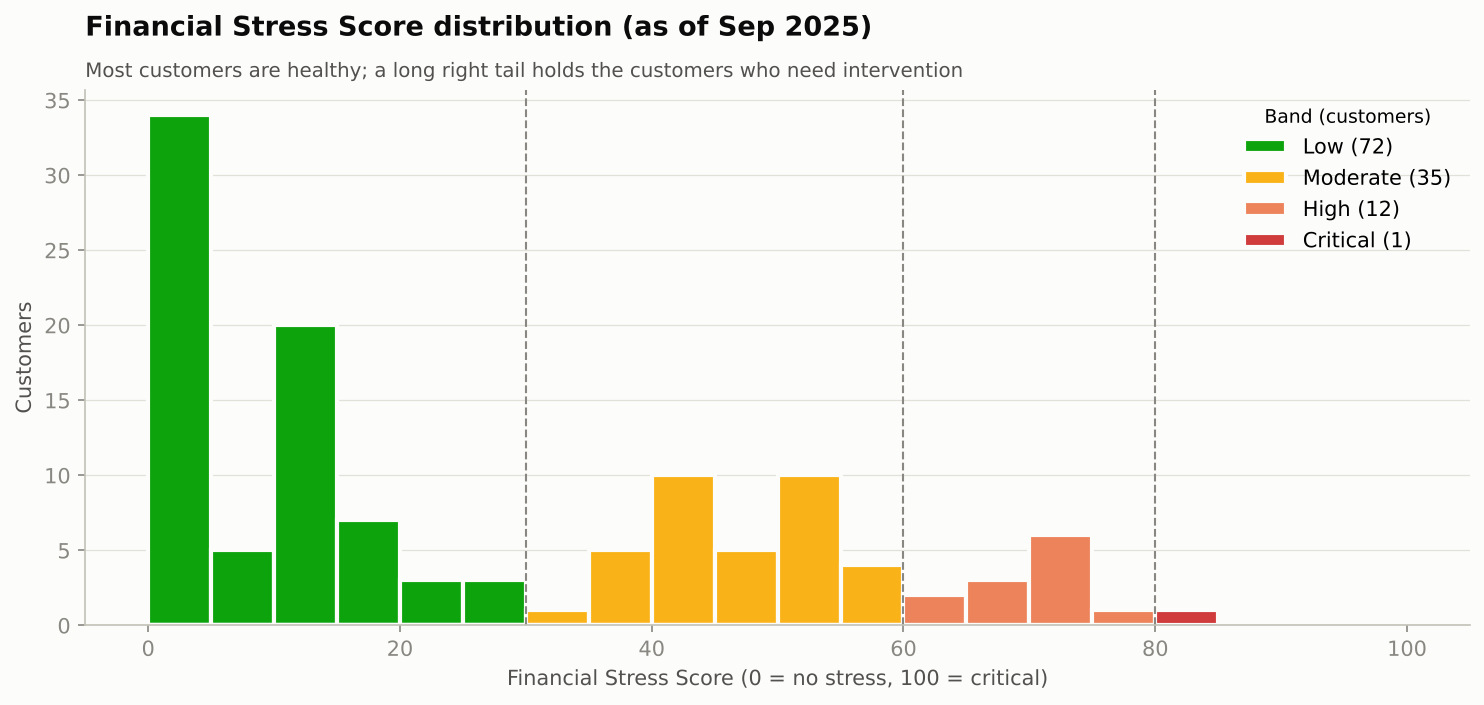

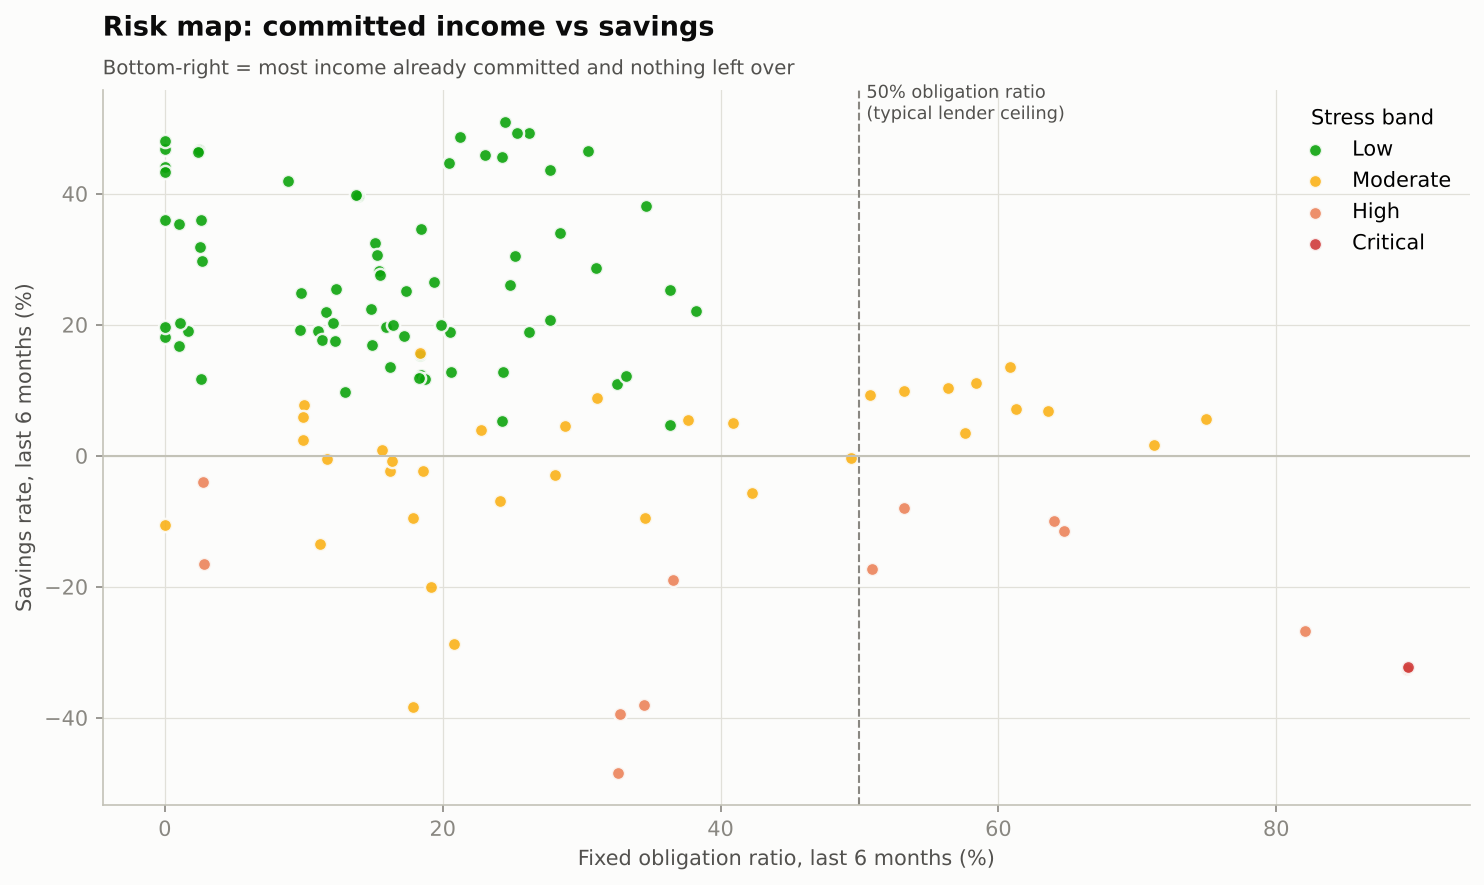

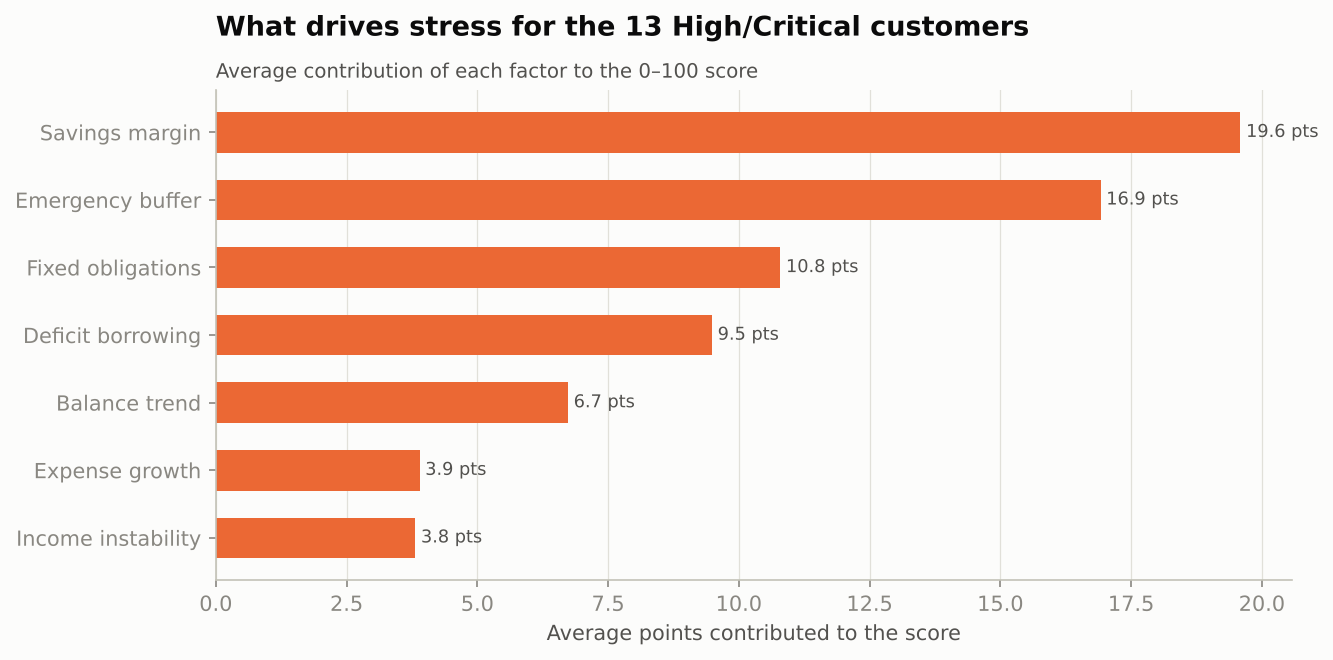

In [4]:
display(Image(ROOT / "reports/figures/10_stress_score_distribution.png", width=850))
display(Image(ROOT / "reports/figures/11_risk_map.png", width=850))
display(Image(ROOT / "reports/figures/12_stress_drivers.png", width=750))

## Validation
Are the scores meaningful? See notebook 06 and `reports/model_validation.md`.